## Developing a better forecast of returns 15:50 - 16:00pm

### Collecting Data

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
with open("../top_100_universe.txt", "r") as f:
    ACTIVE_SET = [line.strip() for line in f]
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty", "paired_qty", "ref_price"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)),
            pl.col("symbol").is_in(ACTIVE_SET))
)

# trades with the bbo
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(13,30), pl.time(21,0)),
            pl.col("symbol").is_in(ACTIVE_SET))
    .with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .with_columns(pl.col("symbol").cast(pl.Categorical))
)

# statistics (for the official closing auction price)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col("stat_type") == 11,
            pl.col("symbol").is_in(ACTIVE_SET))
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


In [2]:
# from datetime import timedelta

# # WHEN CAN WE ACT?  norm_rank_net_imb is a CROSS-SECTIONAL rank, so it cannot be computed from one
# # name's print -- it needs the whole day's cross-section.  The decision time is therefore GLOBAL per
# # day: the day's LAST NOII print (p50 144ms, p90 176ms, max 349ms past 15:50:00), plus latency for
# # compute + routing.  Pegging to each name's own ts_signal is wrong (we couldn't have ranked yet)
# # and a fixed clock window is wrong (print times vary by name, so the slow tail leaks).
# ENTRY_LATENCY = timedelta(microseconds=100)   # AFTER the cross-section is complete: solve + route
# QUOTE_LOOKBACK = timedelta(minutes=5)         # how stale a resting quote may be before we give up

# avg_daily_dollar_volume = (
#     df_trades
#     .select((["ts_event", "symbol", "price", "size"]))
#     .with_columns(pl.col("ts_event").dt.date().alias("date"))
#     .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
#     .group_by(["date", "symbol"])
#     .agg(
#     (pl.col('size') * pl.col("price")).sum().alias("day_volume")
#     )
#     .sort(["date", "symbol"])
#     .with_columns(
#     pl.col("day_volume").ewm_mean(span=10, adjust=True).shift(1).over("symbol", order_by="date").alias("ADV")
#     )
#     .drop("day_volume")
#     .collect(engine="streaming")
# )

# auction = (
#     df_stats
#     .with_columns(
#         pl.col("ts_event").dt.date().alias("date")
#     )
#     .select("date", "symbol", "price")
#     .rename({"price": "auction_price"})
#     .collect(engine="streaming")
# )

# # The signal: each name's FIRST NOII print at/after 15:50:00.  NOII keeps updating until the close,
# # so sort by ts_event first -- .first() must be the earliest print, not just the first row on disk.
# imb_print = (
#     df_imbalance
#     .filter(pl.col("ts_event").dt.time() >= pl.time(15,50,00))
#     .with_columns(pl.col("ts_event").dt.date().alias("date"))
#     .sort("ts_event")
#     .group_by(["date", "symbol"], maintain_order=True)
#     .agg(
#         pl.col("ts_event").first().alias("ts_signal"),
#         pl.col(["side", "total_imbalance_qty", "paired_qty", "ref_price"]).first()
#     )
#     .collect(engine="streaming")
# )

# # The cross-section is only complete once the SLOWEST name that day has printed.
# day_ready = imb_print.group_by("date").agg(pl.col("ts_signal").max().alias("ts_ready"))

# # Candidate entry quotes.  Sorted by ts_event because join_asof requires it and the tbbo parquet is
# # stored in ts_recv order (ts_event has small backward steps).  ts_entry duplicates ts_event so the
# # join key can be consumed and we still keep the realized quote timestamp for the guard below.
# entry_quote_stream = (
#     df_trades
#     .with_columns(
#         pl.col("ts_event").dt.date().alias("date"),
#         ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
#     )
#     .with_columns(
#         ((pl.col("ask_px_00") - pl.col("bid_px_00")) / pl.col("mid")).alias("spread_return")
#     )
#     .filter(pl.col("ts_event").dt.time() >= pl.time(15,45,00))
#     .select(["date", "symbol", "ts_event", "mid", "spread_return"])
#     .with_columns(pl.col("ts_event").alias("ts_entry"))
#     .sort("ts_event")
#     .collect(engine="streaming")
# )

# # Entry = the PREVAILING quote at the decision instant.  strategy="backward" forward-fills the last
# # known BBO -- we do not wait for the next trade to print.
# # cast_time_unit: adding a timedelta promotes ns -> us, and join_asof needs identical key dtypes.
# entry_quotes = (
#     imb_print
#     .join(day_ready, on="date")
#     .with_columns(
#         (pl.col("ts_ready") + ENTRY_LATENCY)
#         .dt.cast_time_unit(entry_quote_stream.schema["ts_event"].time_unit)
#         .alias("ts_decision")
#     )
#     .sort("ts_decision")
#     .join_asof(
#         entry_quote_stream,
#         left_on="ts_decision",
#         right_on="ts_event",
#         by=["date", "symbol"],
#         strategy="backward",
#         tolerance=QUOTE_LOOKBACK,
#     )
#     .rename({"mid": "entry_price"})
# )

# # tbbo is TRADE-conditioned (the BBO sampled at trades), not a true quote feed.  For a name that
# # hasn't traded since its own print, the forward-filled "prevailing" quote is a PRE-print price --
# # knowable, but unfillable, because the book already repriced on the print.  Using it hands the
# # strategy the ~8bp print jump for free, which is the original look-ahead.  So drop those.
# _n_signals = entry_quotes.height
# _no_quote  = entry_quotes.filter(pl.col("ts_entry").is_null()).height
# _pre_print = entry_quotes.filter(pl.col("ts_entry") < pl.col("ts_signal")).height
# entry_quotes = entry_quotes.filter(pl.col("ts_entry") >= pl.col("ts_signal"))

# close_trades = entry_quotes.select(["date", "symbol", "ts_entry", "entry_price", "spread_return"])

# recent_return = (3
#     df_trades
#     .with_columns(pl.col("ts_event").dt.date().alias("date"),
#                   ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
#     .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
#     .group_by(["date", "symbol"], maintain_order=True)
#     .agg(
#         (pl.col("mid").last() - pl.col("mid").first())/pl.col("mid").first()
#     )
#     .rename({"mid":"recent_return"})
#     .collect(engine="streaming")
# )

# # --- Leak guard.  This whole bug class is timestamp alignment, so make it load-bearing. ---
# assert entry_quotes.filter(pl.col("ts_entry") < pl.col("ts_signal")).height == 0
# assert entry_quotes.filter(pl.col("ts_entry") > pl.col("ts_decision")).height == 0
# _stale_ms = (entry_quotes["ts_decision"] - entry_quotes["ts_entry"]).dt.total_microseconds() / 1000
# _ready_ms = ((day_ready["ts_ready"] - day_ready["ts_ready"].dt.truncate("1d")).dt.total_microseconds() / 1000
#              - (15 * 60 + 50) * 60 * 1000)
# print(f"cross-section complete (ms past 15:50:00):  p50 {_ready_ms.median():.0f}  "
#       f"p90 {_ready_ms.quantile(0.90):.0f}  max {_ready_ms.max():.0f}")
# print(f"quote staleness at decision (ms):  p50 {_stale_ms.median():.0f}  "
#       f"p90 {_stale_ms.quantile(0.90):.0f}  p99 {_stale_ms.quantile(0.99):.0f}")
# print(f"name-days: {_n_signals} signals -> {entry_quotes.height} usable  "
#       f"({_pre_print} dropped: quote predates the print, {_no_quote} dropped: no quote)")

In [3]:
# data = (
#     imb_print
#     .join(close_trades, on=["date", "symbol"])
#     .join(auction, on=["date", "symbol"])
#     .join(avg_daily_dollar_volume, on=["date", "symbol"])
#     .join(recent_return, on=["date", "symbol"])
#     .sort(["date", "symbol"])
#     .with_columns(
#         (pl.col("total_imbalance_qty") * pl.col("ref_price")).alias("dollar_imbalance"),
#         (pl.col("paired_qty") * pl.col("ref_price")).alias("paired_dollars"),
#         (
#             pl.when(pl.col("side") == "B").then(1)
#             .when(pl.col("side") == "A").then(-1)
#             .when(pl.col("side") == "N").then(0)
#         ).alias("sign"),
#     )
#     .with_columns(
#         (
#             pl.col("sign") * pl.col("dollar_imbalance")
#         ).alias("signed_dollar_imbalance")
#     )
#     .drop(["total_imbalance_qty"])
#     .drop_nulls()
#     .with_columns(
#         (
#             (pl.col("paired_dollars") / pl.col("ADV"))
#         ).alias("auction_dollar_volume_ratio"),
#         (
#             pl.when(pl.col("paired_dollars") != 0).then(pl.col("signed_dollar_imbalance") / pl.col("paired_dollars"))
#             .otherwise(0)
#         ).alias("net_signed_imb"),
#         (
#             (pl.col("auction_price") - pl.col("entry_price")) / pl.col("entry_price")
#         ).alias("return_to_close")
#     )
#     .with_columns(
#         pl.col("net_signed_imb").rank().over(pl.col("date")).alias("rank_net_imb")
#     )
#     .with_columns(
#         (pl.col("return_to_close") - pl.col("return_to_close").mean().over("date")).alias("close_return_xm"),
#         (pl.col("recent_return") - pl.col("recent_return").mean().over("date")).alias("recent_return_xm"),
#         (pl.col("auction_dollar_volume_ratio") - pl.col("auction_dollar_volume_ratio").mean().over("date")).alias("auction_dollar_volume_ratio_xm"),
#         (
#             ((pl.col("net_signed_imb").rank().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date"))) 
#              / (pl.col("net_signed_imb").rank().max().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date"))))
#              * 2 - 1
#         ).alias("norm_rank_net_imb"),
#     )
#     .with_columns(
#         (pl.col("norm_rank_net_imb") * pl.col("recent_return_xm")).alias("norm_rank_net_x_recent_xm"),
#         (pl.col("auction_dollar_volume_ratio_xm") * pl.col("norm_rank_net_imb")).alias("norm_rank_net_x_auction"),
#         (pl.col("auction_dollar_volume_ratio_xm") * pl.col("recent_return_xm")).alias("auction_x_recent_xm")
#     )
# )

# data

In [4]:
avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .sort(["date", "symbol"])
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).shift(1).over("symbol").alias("ADV")
    )
    .drop("day_volume")
    .collect(engine="streaming")
)

# Causal per-(date, symbol) daily volatility: EWMA of squared daily returns, SHIFTED 1 day (uses only
# past info) -- same causal recipe as ADV.  sigma_{i,d} = sqrt( EWMA(day_ret^2) )_{d-1}, day close = last mid.
daily_vol = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,0)))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(pl.col("mid").last().alias("close"))
    .sort(["date", "symbol"])
    .with_columns(pl.col("close").pct_change().over("symbol").alias("day_ret"))
    .with_columns(
        pl.col("day_ret").pow(2).ewm_mean(span=10, adjust=True).shift(1).over("symbol").sqrt().alias("vol")
    )
    .select(["date", "symbol", "vol"])
    .collect(engine="streaming")
)

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date")
    )
    .select("date", "symbol", "price")
    .rename({"price": "auction_price"})
    .collect(engine="streaming")
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid")
    )
    .with_columns(
        ((pl.col("ask_px_00") - pl.col("bid_px_00")) / pl.col("mid")).alias("spread_return")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,50,00), pl.time(15,55,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col("ts_event").first().alias("ts_entry"),
        pl.col(["mid"]).first(),
        pl.col(["spread_return"]).first()
    )
    .rename({"mid":"entry_price"})
    .collect(engine="streaming")
)

recent_return = (
    df_trades
    .with_columns(pl.col("ts_event").dt.date().alias("date"),
                  ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        (pl.col("mid").last() - pl.col("mid").first())/pl.col("mid").first()
    )
    .rename({"mid":"recent_return"})
    .collect(engine="streaming")
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,50,00), pl.time(15,55,0)))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col("ts_event").first().alias("ts_signal"),
        pl.col(["side", "total_imbalance_qty", "paired_qty", "ref_price"]).first()
    )
    .collect(engine="streaming")
)

In [5]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .join(daily_vol, on=["date", "symbol"])
    .join(recent_return, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .with_columns(
        (pl.col("total_imbalance_qty") * pl.col("ref_price")).alias("dollar_imbalance"),
        (pl.col("paired_qty") * pl.col("ref_price")).alias("paired_dollars"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
        ).alias("sign"),
    )
    .with_columns(
        (
            pl.col("sign") * pl.col("dollar_imbalance")
        ).alias("signed_dollar_imbalance")
    )
    .drop(["total_imbalance_qty"])
    .drop_nulls()
    .with_columns(
        (
            (pl.col("paired_dollars") / pl.col("ADV"))
        ).alias("auction_dollar_volume_ratio"),
        (
            pl.when(pl.col("paired_dollars") != 0).then(pl.col("signed_dollar_imbalance") / pl.col("paired_dollars"))
            .otherwise(0)
        ).alias("net_signed_imb"),
        (
            (pl.col("auction_price") - pl.col("entry_price")) / pl.col("entry_price")
        ).alias("return_to_close")
    )
    .with_columns(
        pl.col("net_signed_imb").rank().over(pl.col("date")).alias("rank_net_imb")
    )
    .with_columns(
        (pl.col("return_to_close") - pl.col("return_to_close").mean().over("date")).alias("close_return_xm"),
        (pl.col("recent_return") - pl.col("recent_return").mean().over("date")).alias("recent_return_xm"),
        (pl.col("auction_dollar_volume_ratio") - pl.col("auction_dollar_volume_ratio").mean().over("date")).alias("auction_dollar_volume_ratio_xm"),
        (
            ((pl.col("net_signed_imb").rank().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date"))) 
                / (pl.col("net_signed_imb").rank().max().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date"))))
                * 2 - 1
        ).alias("norm_rank_net_imb"),
    )
    .with_columns(
        (pl.col("norm_rank_net_imb") * pl.col("recent_return_xm")).alias("norm_rank_net_x_recent_xm"),
        (pl.col("auction_dollar_volume_ratio_xm") * pl.col("norm_rank_net_imb")).alias("norm_rank_net_x_auction"),
        (pl.col("auction_dollar_volume_ratio_xm") * pl.col("recent_return_xm")).alias("auction_x_recent_xm")
    )
)

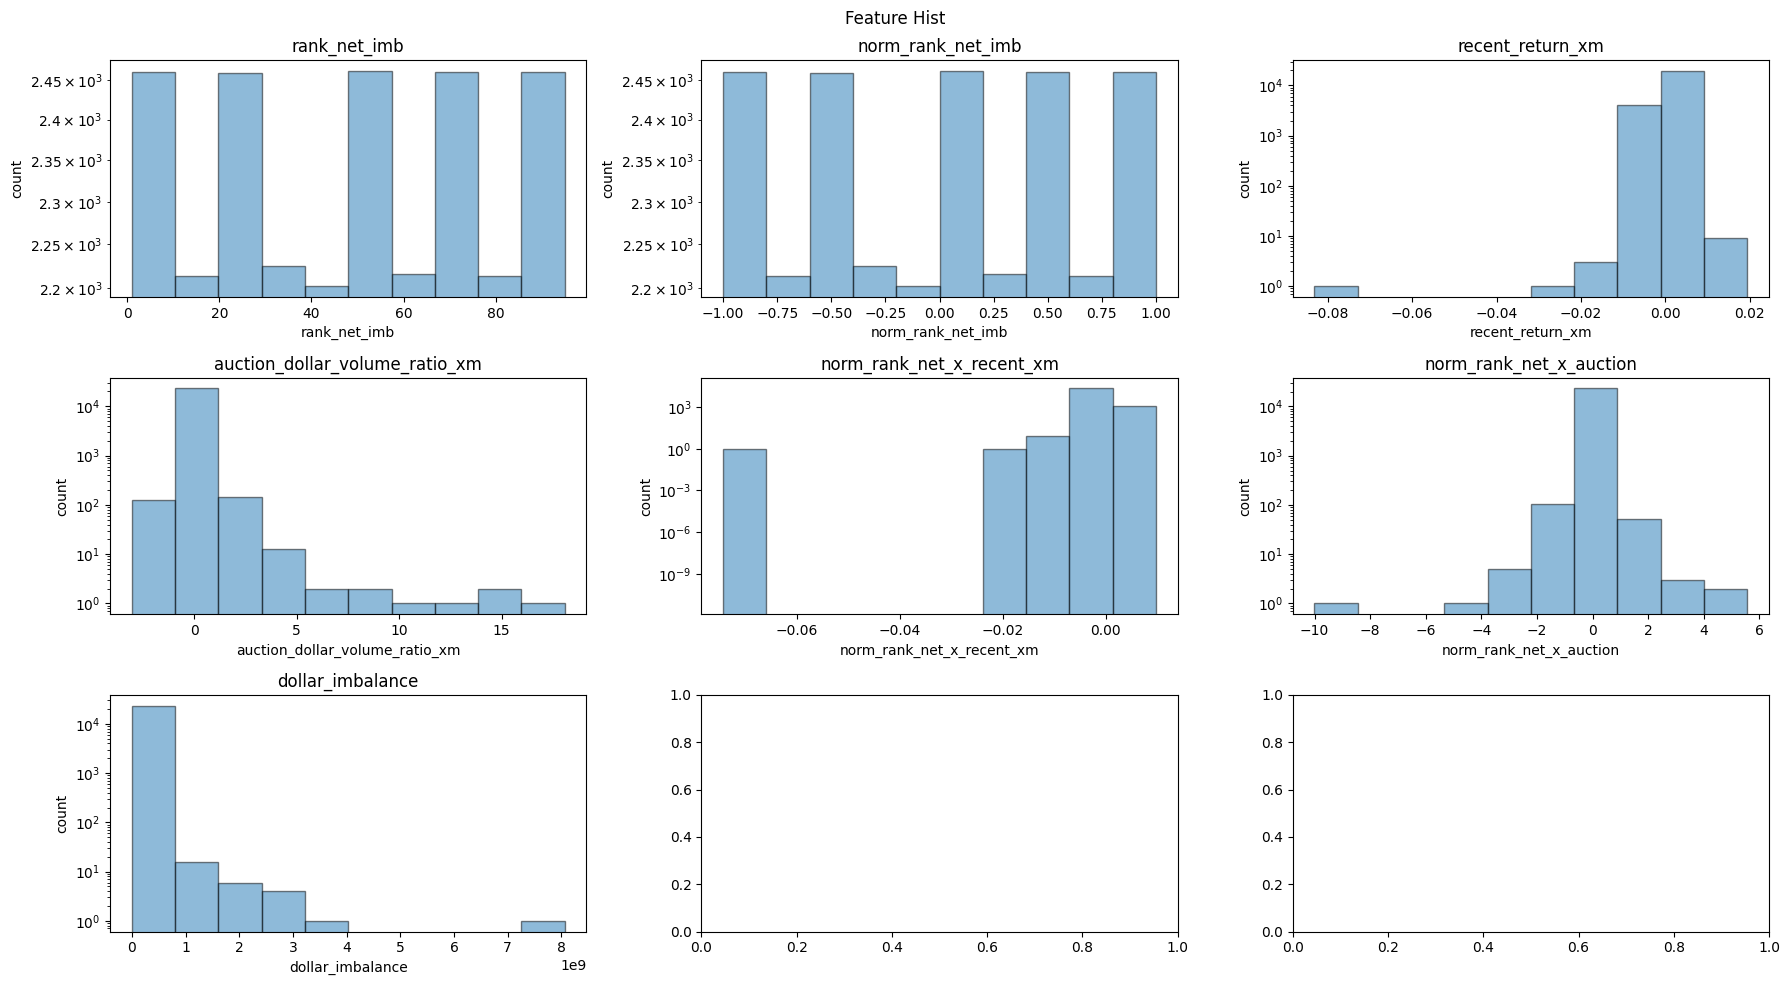

In [6]:
plot_features = [
    "rank_net_imb",
    "norm_rank_net_imb", 
    "recent_return_xm",
    "auction_dollar_volume_ratio_xm",
    "norm_rank_net_x_recent_xm",
    "norm_rank_net_x_auction",
    "dollar_imbalance"
]
log_x = plot_features

fig, axes = plt.subplots(3, 3, figsize=(18, 10))
for ax, feat in zip(axes.flat, plot_features):
    x = data[feat].to_numpy()
    ax.hist(x, alpha=0.5, edgecolor="black")
    ax.axhline(0, color="grey", lw=0.5)
    if feat in log_x:
        # ax.set_xscale("log")
        ax.set_yscale("log")
    ax.set_xlabel(feat)
    ax.set_ylabel("count")
    ax.set_title(f"{feat}")

fig.suptitle("Feature Hist")
fig.tight_layout()
plt.show()

In [7]:
data.filter(pl.col("auction_dollar_volume_ratio") == pl.col("auction_dollar_volume_ratio").max())

date,symbol,ts_signal,side,paired_qty,ref_price,ts_entry,entry_price,spread_return,auction_price,ADV,vol,recent_return,dollar_imbalance,paired_dollars,sign,signed_dollar_imbalance,auction_dollar_volume_ratio,net_signed_imb,return_to_close,rank_net_imb,close_return_xm,recent_return_xm,auction_dollar_volume_ratio_xm,norm_rank_net_imb,norm_rank_net_x_recent_xm,norm_rank_net_x_auction,auction_x_recent_xm
date,cat,"datetime[ns, America/New_York]",str,u32,f64,"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,i32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-08-27,"""IBKR""",2025-08-27 15:50:00.076856825 EDT,"""A""",24472001,61.47,2025-08-27 15:50:00.020878726 EDT,61.47,0.000325,61.79,8.1244e7,0.01467,-0.00065,1.7289e8,1.5043e9,-1,-1.7289e8,18.51567,-0.114929,0.005206,22.0,0.005293,-0.000874,18.082809,-0.553191,0.000483,-10.003256,-0.0158


## Cross Validation

In [8]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge, LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error
from scipy.stats import spearmanr
import statsmodels.api as sm
from sklearn.metrics.pairwise import cosine_similarity
import xgboost as xgb



# Split on unique DATES (not rows): one day's cross-section must stay whole,
# otherwise the same date leaks across train/test.
dates = data["date"].unique().sort().to_list()
feature_sets = [
    [
        "rank_net_imb"
    ],
    [
        "norm_rank_net_imb"
    ],
    [
        "norm_rank_net_imb", 
        "recent_return_xm", 
        "norm_rank_net_x_recent_xm",
    ],
    [
        "norm_rank_net_imb", 
        "auction_dollar_volume_ratio_xm",
        "norm_rank_net_x_auction",

    ],
    [
        "norm_rank_net_imb", 
        "recent_return_xm",
        "auction_dollar_volume_ratio_xm", 
        "norm_rank_net_x_recent_xm",
        "norm_rank_net_x_auction",
    ],
]
target = ["close_return_xm"]


for features in feature_sets:
    tscv = TimeSeriesSplit(n_splits=8, max_train_size=120, test_size=30)  # rolling ~train window
    scaler = StandardScaler()
    fold_ics = []
    fold_metrics = []
    all_daily_ics = []
    stds = []
    for i, (train_d, test_d) in enumerate(tscv.split(dates)):
        train_dates = [dates[j] for j in train_d]
        test_dates  = [dates[j] for j in test_d]

        train = data.filter(pl.col("date").is_in(train_dates))
        test  = data.filter(pl.col("date").is_in(test_dates))

        X_train_scale = scaler.fit_transform(train[features].to_numpy())
        y_train = train[target].to_numpy()
        X_test_scale = scaler.transform(test[features].to_numpy())
        y_test = test[target].to_numpy()

        # --- Main Model ---
        linear_model = Lasso(alpha=1e-4)
        linear_model.fit(X_train_scale, y_train)
        y_hat_linear = linear_model.predict(X_test_scale).reshape(-1,1)
        resid_linear = linear_model.predict(X_train_scale).reshape(-1,1) - y_train

        # --- Adding a Boosted Model ---
        xgb_model = xgb.XGBRegressor(
            booster='gbtree',
            n_estimators=50,      # Number of boosting rounds (trees)
            max_depth=4,           # Maximum tree depth
            learning_rate=0.01,    # Step size shrinkage (eta)
            reg_alpha = 1e-6,
            reg_lambda = 1e-10,
            objective='reg:squarederror', # Loss function for regression
            tree_method='hist',    # Optimized tree construction method
            random_state=42
        )
        xgb_model.fit(X_train_scale, resid_linear)
        y_hat_xgb = xgb_model.predict(X_test_scale).reshape(-1,1)

        # --- Forecast Combination (Simple) ---
        y_hat = (y_hat_linear - y_hat_xgb)

        # Forecast on test, then daily cross-sectional rank IC (Spearman), MSE, MAE, and R^2, averaged.
        pred_df = (
            test
            .with_columns(pl.Series("yhat", y_hat))
        )
        daily_ic = (
            pred_df.group_by("date")
            .agg(
                pl.map_groups(
                    exprs=["yhat", target[0]],
                    function=lambda s: spearmanr(s[0], s[1]).statistic,
                    return_dtype=pl.Float64,
                    returns_scalar=True,
                ).alias("ic")
            )
            .drop_nulls()
        )
        y_hat_reshape, y_test_reshape = y_hat.reshape(1,-1), y_test.reshape(1,-1)
        sim = cosine_similarity(y_hat_reshape, y_test_reshape)
        mean_ic = daily_ic["ic"].mean()
        fold_ics.append(mean_ic)
        rmse, mae = root_mean_squared_error(y_test, y_hat), mean_absolute_error(y_test, y_hat)
        fold_metrics.append(
            (rmse, mae, sim)
        )
        stds.append(np.std(y_hat) / np.std(y_test))
        all_daily_ics.extend(daily_ic["ic"].to_list())

    print(
        f"\n{features}"
        f"\nMean/Std IC across folds: {np.mean(fold_ics):+.4f}/{np.std(fold_ics):+.4f}"
        f"   (IR = {np.mean(fold_ics) / np.std(fold_ics):+.2f})"
        f"\nMean RMSE across folds: {np.mean([rmse for (rmse, mae, sim) in fold_metrics]):.3e}"
        f"\nMean Cosine Similarity across folds: {np.mean([sim for (rmse, mae, sim) in fold_metrics]):.3f}"
        )


['rank_net_imb']
Mean/Std IC across folds: +0.2544/+0.0320   (IR = +7.96)
Mean RMSE across folds: 3.022e-03
Mean Cosine Similarity across folds: 0.247

['norm_rank_net_imb']
Mean/Std IC across folds: +0.2544/+0.0320   (IR = +7.96)
Mean RMSE across folds: 3.022e-03
Mean Cosine Similarity across folds: 0.247

['norm_rank_net_imb', 'recent_return_xm', 'norm_rank_net_x_recent_xm']
Mean/Std IC across folds: +0.2489/+0.0278   (IR = +8.94)
Mean RMSE across folds: 3.033e-03
Mean Cosine Similarity across folds: 0.235

['norm_rank_net_imb', 'auction_dollar_volume_ratio_xm', 'norm_rank_net_x_auction']
Mean/Std IC across folds: +0.2553/+0.0309   (IR = +8.25)
Mean RMSE across folds: 3.026e-03
Mean Cosine Similarity across folds: 0.244

['norm_rank_net_imb', 'recent_return_xm', 'auction_dollar_volume_ratio_xm', 'norm_rank_net_x_recent_xm', 'norm_rank_net_x_auction']
Mean/Std IC across folds: +0.2483/+0.0266   (IR = +9.32)
Mean RMSE across folds: 3.029e-03
Mean Cosine Similarity across folds: 0.238


In [9]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge, LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error
from scipy.stats import spearmanr
import statsmodels.api as sm
from sklearn.metrics.pairwise import cosine_similarity
import xgboost as xgb



# Split on unique DATES (not rows): one day's cross-section must stay whole,
# otherwise the same date leaks across train/test.
dates = data["date"].unique().sort().to_list()
feature_sets = [
    [
        "rank_net_imb"
    ],
    [
        "norm_rank_net_imb"
    ],
    [
        "norm_rank_net_imb", 
        "recent_return_xm", 
        "norm_rank_net_x_recent_xm",
    ],
    [
        "norm_rank_net_imb", 
        "auction_dollar_volume_ratio_xm",
        "norm_rank_net_x_auction",

    ],
    [
        "norm_rank_net_imb", 
        "recent_return_xm",
        "auction_dollar_volume_ratio_xm", 
        "norm_rank_net_x_recent_xm",
        "norm_rank_net_x_auction",
    ],
]
target = ["close_return_xm"]

for features in feature_sets:
    tscv = TimeSeriesSplit(n_splits=49, max_train_size=120, test_size=5)  # rolling ~train window
    scaler = StandardScaler()
    fold_ics = []
    fold_metrics = []
    all_daily_ics = []
    stds = []
    for i, (train_d, test_d) in enumerate(tscv.split(dates)):
        train_dates = [dates[j] for j in train_d]
        test_dates  = [dates[j] for j in test_d]

        train = data.filter(pl.col("date").is_in(train_dates))
        test  = data.filter(pl.col("date").is_in(test_dates))

        X_train_scale = scaler.fit_transform(train[features].to_numpy())
        y_train = train[target].to_numpy()
        X_test_scale = scaler.transform(test[features].to_numpy())
        y_test = test[target].to_numpy()

        # --- Main Model ---
        linear_model = Lasso(alpha=1e-4)
        linear_model.fit(X_train_scale, y_train)
        y_hat_linear = linear_model.predict(X_test_scale).reshape(-1,1)

        # --- Forecast Combination (Simple) ---
        y_hat = y_hat_linear

        # Forecast on test, then daily cross-sectional rank IC (Spearman), MSE, MAE, and R^2, averaged.
        pred_df = (
            test
            .with_columns(pl.Series("yhat", y_hat))
        )
        daily_ic = (
            pred_df.group_by("date")
            .agg(
                pl.map_groups(
                    exprs=["yhat", target[0]],
                    function=lambda s: spearmanr(s[0], s[1]).statistic,
                    return_dtype=pl.Float64,
                    returns_scalar=True,
                ).alias("ic")
            )
            .drop_nulls()
        )
        y_hat_reshape, y_test_reshape = y_hat.reshape(1,-1), y_test.reshape(1,-1)
        sim = cosine_similarity(y_hat_reshape, y_test_reshape)
        mean_ic = daily_ic["ic"].mean()
        fold_ics.append(mean_ic)
        rmse, mae = root_mean_squared_error(y_test, y_hat), mean_absolute_error(y_test, y_hat)
        fold_metrics.append(
            (rmse, mae, sim)
        )
        stds.append(np.std(y_hat) / np.std(y_test))
        all_daily_ics.extend(daily_ic["ic"].to_list())

    print(
        f"\n{features}"
        f"\nMean/Std IC across folds: {np.mean(fold_ics):+.4f}/{np.std(fold_ics):+.4f}"
        f"   (IR = {np.mean(fold_ics) / np.std(fold_ics):+.2f})"
        f"\nMean RMSE across folds: {np.mean([rmse for (rmse, mae, sim) in fold_metrics]):.3e}"
        f"\nMean Cosine Similarity across folds: {np.mean([sim for (rmse, mae, sim) in fold_metrics]):.3f}"
        )


['rank_net_imb']
Mean/Std IC across folds: +0.2551/+0.0589   (IR = +4.33)
Mean RMSE across folds: 2.977e-03
Mean Cosine Similarity across folds: 0.249

['norm_rank_net_imb']
Mean/Std IC across folds: +0.2551/+0.0589   (IR = +4.33)
Mean RMSE across folds: 2.977e-03
Mean Cosine Similarity across folds: 0.249

['norm_rank_net_imb', 'recent_return_xm', 'norm_rank_net_x_recent_xm']
Mean/Std IC across folds: +0.2474/+0.0584   (IR = +4.24)
Mean RMSE across folds: 2.984e-03
Mean Cosine Similarity across folds: 0.238

['norm_rank_net_imb', 'auction_dollar_volume_ratio_xm', 'norm_rank_net_x_auction']
Mean/Std IC across folds: +0.2529/+0.0604   (IR = +4.19)
Mean RMSE across folds: 2.986e-03
Mean Cosine Similarity across folds: 0.245

['norm_rank_net_imb', 'recent_return_xm', 'auction_dollar_volume_ratio_xm', 'norm_rank_net_x_recent_xm', 'norm_rank_net_x_auction']
Mean/Std IC across folds: +0.2452/+0.0596   (IR = +4.11)
Mean RMSE across folds: 2.992e-03
Mean Cosine Similarity across folds: 0.234


In [10]:
print(f"Mean of y_test: {np.mean(np.abs(y_test)):.3e}")

Mean of y_test: 3.849e-03


## Training, Validation, and Persistence

In [11]:
data

date,symbol,ts_signal,side,paired_qty,ref_price,ts_entry,entry_price,spread_return,auction_price,ADV,vol,recent_return,dollar_imbalance,paired_dollars,sign,signed_dollar_imbalance,auction_dollar_volume_ratio,net_signed_imb,return_to_close,rank_net_imb,close_return_xm,recent_return_xm,auction_dollar_volume_ratio_xm,norm_rank_net_imb,norm_rank_net_x_recent_xm,norm_rank_net_x_auction,auction_x_recent_xm
date,cat,"datetime[ns, America/New_York]",str,u32,f64,"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,i32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-13,"""AAPL""",2025-06-13 15:50:00.098401021 EDT,"""B""",3248433,196.25,2025-06-13 15:50:00.007874191 EDT,196.125,0.000051,196.45,1.8347e9,0.00176,0.000383,4000752.5,6.3750e8,1,4000752.5,0.347476,0.006276,0.001657,57.0,0.001188,-0.000076,0.023211,0.191489,-0.000015,0.004445,-0.000002
2025-06-13,"""ABNB""",2025-06-13 15:50:00.009094341 EDT,"""B""",415587,135.01,2025-06-13 15:50:00.009206943 EDT,134.985,0.00037,135.54,1.0917e8,0.005432,0.001038,2.6115e7,5.6108e7,1,2.6115e7,0.513947,0.465433,0.004112,87.0,0.003642,0.00058,0.189681,0.829787,0.000481,0.157395,0.00011
2025-06-13,"""ADBE""",2025-06-13 15:50:00.091838977 EDT,"""B""",218747,391.59,2025-06-13 15:50:00.014716486 EDT,391.32,0.000613,391.68,3.2366e8,0.003077,0.000729,2.8642e7,8.5659e7,1,2.8642e7,0.264654,0.334373,0.00092,85.0,0.000451,0.00027,-0.059611,0.787234,0.000213,-0.046928,-0.000016
2025-06-13,"""ADI""",2025-06-13 15:50:00.057147152 EDT,"""A""",298400,225.3,2025-06-13 15:50:00.011898046 EDT,225.33,0.000444,225.03,1.2360e8,0.002322,0.001623,1.4033937e7,6.722952e7,-1,-1.4033937e7,0.543906,-0.208747,-0.001331,23.0,-0.001801,0.001164,0.219641,-0.531915,-0.000619,-0.11683,0.000256
2025-06-13,"""ADP""",2025-06-13 15:50:00.110733695 EDT,"""A""",127358,305.98,2025-06-13 15:50:00.029536853 EDT,306.02,0.000327,306.82,9.1821e7,0.008116,-0.000147,5.4605e6,3.8969e7,-1,-5.4605e6,0.424402,-0.140125,0.002614,32.0,0.002145,-0.000606,0.100137,-0.340426,0.000206,-0.034089,-0.000061
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-10,"""ULTA""",2026-06-10 15:50:00.093100557 EDT,"""B""",19855,470.25,2026-06-10 15:50:00.022816803 EDT,470.2,0.000213,470.75,9.8677e7,0.02367,0.000234,2.1693e6,9.3368e6,1,2.1693e6,0.09462,0.232334,0.00117,88.0,0.003355,0.000737,-0.298331,0.851064,0.000627,-0.253898,-0.00022
2026-06-10,"""VRTX""",2026-06-10 15:50:00.130783173 EDT,"""A""",160879,434.34,2026-06-10 15:50:00.027765732 EDT,434.495,0.000529,435.71,1.0365e8,0.016127,-0.001758,7.5115e6,6.9876e7,-1,-7.5115e6,0.674156,-0.107497,0.002796,34.0,0.004982,-0.001255,0.281205,-0.297872,0.000374,-0.083763,-0.000353
2026-06-10,"""WDAY""",2026-06-10 15:50:00.114329290 EDT,"""A""",262562,137.6,2026-06-10 15:50:00.004587642 EDT,137.7,0.00029,137.47,1.7716e8,0.040454,-0.00029,5616556.8,3.6129e7,-1,-5.6166e6,0.203937,-0.15546,-0.00167,27.0,0.000515,0.000213,-0.189013,-0.446809,-0.000095,0.084453,-0.00004


In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge, LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import spearmanr
import statsmodels.api as sm

train_data = data.filter(pl.col("date").is_between(pl.date(2025,6,11), pl.date(2026,1,1), closed="left"))
val_data = data.filter(pl.col("date").is_between(pl.date(2026,1,1), pl.date(2026,2,1), closed="left"))

features = ['norm_rank_net_imb', 'auction_dollar_volume_ratio_xm', 'norm_rank_net_x_auction']

target = ["close_return_xm"]

scaler = StandardScaler()
X_train_scale = scaler.fit_transform(train_data[features].to_numpy())
y_train = train_data[target].to_numpy()
X_val_scale = scaler.transform(val_data[features].to_numpy())
y_val = val_data[target].to_numpy()

model = Lasso(alpha=1e-4)
model.fit(X_train_scale, y_train)
y_hat = model.predict(X_val_scale).reshape(-1,1)
mse, mae, r2 = mean_squared_error(y_val, y_hat), mean_absolute_error(y_val, y_hat), model.score(X_val_scale, y_val)
ic, _ = spearmanr(y_val, y_hat)

print("Model coefficients:\n")
for i, f in enumerate(features):
    print(f"{f} = {model.coef_[i]:,.10f}")
print(
        f"\n{features}"
        f"\nIC: {ic:+.4f}"
        f"\nR^2: {r2:+.6f}"
        f"\nMSE: {mse:+.3e}"
        f"\nMAE: {mae:+.3e}"
        )

Model coefficients:

norm_rank_net_imb = 0.0006300121
auction_dollar_volume_ratio_xm = 0.0000000000
norm_rank_net_x_auction = 0.0000000000

['norm_rank_net_imb', 'auction_dollar_volume_ratio_xm', 'norm_rank_net_x_auction']
IC: +0.2927
R^2: +0.081954
MSE: +7.053e-06
MAE: +1.969e-03


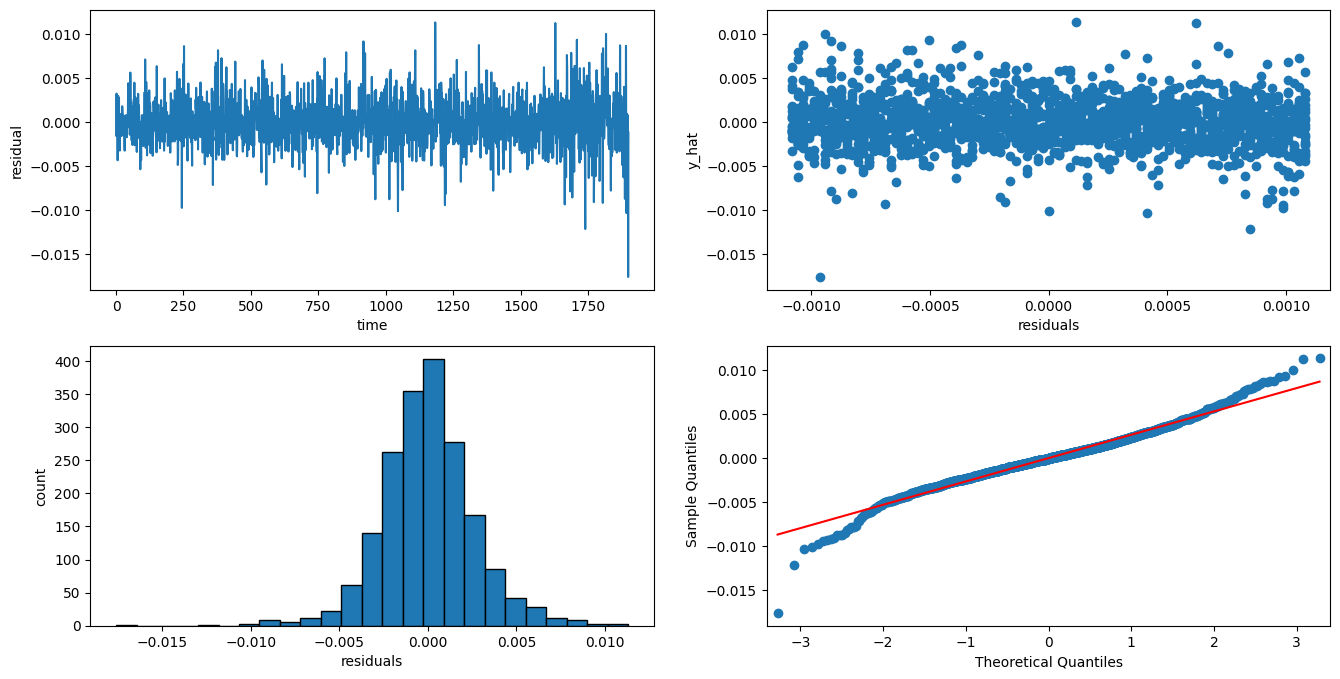

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(16,8))

residuals = y_hat - y_val

ax[0,0].plot(residuals)
ax[0,0].set_xlabel("time")
ax[0,0].set_ylabel("residual")

ax[0,1].scatter(y_hat, residuals)
ax[0,1].set_xlabel("residuals")
ax[0,1].set_ylabel("y_hat")

ax[1,0].hist(residuals, edgecolor='black', bins=25)
ax[1,0].set_xlabel("residuals")
ax[1,0].set_ylabel("count")

sm.qqplot(residuals.flatten(), line='s', ax=ax[1,1])

plt.show()

In [14]:
import joblib
from sklearn.pipeline import make_pipeline

pipe = make_pipeline(StandardScaler(), Lasso(alpha=1e-4))
pipe.fit(train_data[features].to_numpy(), train_data[target].to_numpy())
joblib.dump(pipe, "forecast_pipe.joblib")

['forecast_pipe.joblib']